# Lista de Exercícios 1: Processos de Decisão de Markov e Programação Dinâmica

#### Disciplina: Aprendizado por Reforço
#### Professor: Luiz Chaimowicz
#### Monitores: Marcelo Lemos e Ronaldo Vieira

---

## Instruções

- ***SUBMISSÕES QUE NÃO SEGUIREM AS INSTRUÇÕES A SEGUIR NÃO SERÃO AVALIADAS.***
- Leia atentamente toda a lista de exercícios e familiarize-se com o código fornecido antes de começar a implementação.
- Os locais onde você deverá escrever suas soluções estão demarcados com comentários `# YOUR CODE HERE` ou `YOUR ANSWER HERE`.
- **Não altere o código fora das áreas indicadas, nem adicione ou remova células. O nome deste arquivo também não deve ser modificado.**
- Antes de submeter, certifique-se de que o código esteja funcionando do início ao fim sem erros.
- Submeta apenas este notebook (*ps1.ipynb*) com as suas soluções no Moodle.
- Prazo de entrega: 23/09/2025. Submissões fora do prazo terão uma penalização de -20% da nota final por dia de atraso.
- Utilize a [documentação do Gymnasium](https://gymnasium.farama.org/) para auxiliar sua implementação.
- Em caso de dúvidas entre em contato pelo fórum "Dúvidas com relação aos exercícios e trabalho de curso" no moodle da Disciplina.

---

## Frozen Lake

O ambiente Frozen Lake é uma simulação clássica utilizada para treinamento de agentes em aprendizado por reforço. Neste ambiente, o agente navega por um lago congelado representado por um grid de tamanho $n \times m$, com o objetivo de alcançar um alvo. O lago contém dois tipos de células: (1) células com gelo sólido, que são seguras para o agente se mover, e (2) as células com buracos, nas quais o agente cai e falha a missão. Embora o Gymnasium já possua uma implementação do Frozen Lake, neste exercício iremos implementá-lo do zero.

No início de cada episódio, o agente é posicionado na célula $[0, 0]$ enquanto o alvo é posicionado na célula mais distante do agente, na posição $[n-1, m-1]$ em um mapa de tamanho $n \times m$. A cada passo, o agente recebe uma observação indicando sua posição atual no lago e tem a possibilidade de escolher entre quatro ações possíveis: mover-se para cima, para baixo, para a esquerda ou para a direita. No entanto, devido à superfície escorregadia do lago, ele nem sempre se move na direção desejada, podendo acabar se movendo em uma direção perpendicular à escolhida. O agente recebe uma recompensa de 1 se alcançar o alvo e zero em todos os outros estados. Um episódio termina quando o agente alcança o objetivo ou cai na água.

Neste exercício, vamos trabalhar sempre com o mesmo mapa $4 \times 4$, representado na figura abaixo.

![Frozen Lake Map](https://gymnasium.farama.org/_images/frozen_lake.gif)

Sua primeira tarefa será implementar o ambiente Frozen Lake utilizando o arcabouço fornecido pelo Gymnasium. Abaixo, você encontrará um código inicial que deverá ser utilizado em sua implementação. Siga essas instruções para garantir que seu código está de acordo com o esperado:

1. Na função `__init__`, já definimos o mapa que será utilizado e armazenamos essa informação na variável `_description`. Nesse mapa, a letra 'S' representa a posição inicial do agente, a letra 'G' indica o alvo, as letras 'F' representam gelo sólido (que é seguro) e as letras 'H' marcam os buracos. No entanto, ainda é necessário adicionar mais algumas informações no ambiente, especificamente sobre a representação das observações e das ações. Embora existam várias maneiras de representar os espaços de observações e de ação, neste exercício, você deve usar a forma mais simples possível, que pode ser representada por um único valor discreto. Na função `__init__`, defina o espaço de observações e o espaço de ações, atribuindo-os às variáveis `self.observation_space` e `self.action_space`, respectivamente. Utilize apenas a classe `gymnasium.spaces.Discrete` nesta tarefa.

2. Antes de prosseguirmos com as funcionalidades do gymnasium, vamos implementar algumas funções auxiliares para facilitar as próximas etapas. Implemente a função `_get_obs`, que retorna a observação atual do ambiente. Além disso, implemente a função `_set_state`, que recebe um valor inteiro correspondente a uma posição no lago e coloca o agente nesta localização.

3. A função `reset` deve resetar o ambiente e inicializar um novo episódio, posicionando o agente na célula $[0, 0]$ e fazendo todos os ajustes internos necessários. Esta função deve retornar uma tupla contendo a observação inicial e as informações do ambiente. Neste exercício, vamos retornar um dicionario vazio `{}` para as informações. Lembre-se que a observação deve ser um único valor discreto, como definido no item 1. Implemente a função `reset`.

4. A função `step()` é responsável por atualizar o ambiente com base na ação executada pelo agente. Ela recebe como entrada a ação escolhida pelo agente, um parâmetro seed e uma variável options, e calcula o novo estado atual com base na função de transição previamente definida. Neste exercício, você pode ignorar os parâmetros seed e options, pois não precisaremos deles. Neste ambiente que estamos desenvolvendo, o agente tem 80% de chance de se mover na direção desejada e 20% de chance de se mover em uma direção perpendicular à escolhida, distribuída igualmente entre os dois sentidos possíveis (10% para cada um). **As ações do agente devem ser representadas pelos valores 0 (mover-se para a esquerda), 1 (mover-se para baixo), 2 (mover-se para a direita) e 3 (mover-se para cima)**. Caso o agente tente se mover para fora do mapa, ele permanecerá na mesma posição. Além disso, a função atribui uma recompensa ao agente e verifica se o episódio chegou ao fim. Implemente a função step() para que ela retorne a observação do estado atual, a recompensa recebida, um valor booleano indicando se o estado é terminal, um valor booleano informando se o episódio foi truncado e as informações do ambiente. Esses dois últimos valores são necessários devidio à interface estabelecida pelo gymnasium, mas não se preocupe com eles; apenas retorne sempre `False` e `{}` para eles.

In [ ]:
import sys
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

In [ ]:
class FrozenLake(gym.Env):
    def __init__(self):
        self._description = np.asarray([
            "SFFF",
            "FHFH",
            "FFFH",
            "HFFG"
        ], dtype='c')

        # Número de estados = número de células do mapa (linhas x colunas)
        n_rows, n_cols = self._description.shape
        n_states = n_rows * n_cols

        # Espaço de observação: cada célula é um estado discreto 0..n_states-1
        self.observation_space = gym.spaces.Discrete(n_states)

        # Espaço de ações: 4 ações discretas (0=LEFT,1=DOWN,2=RIGHT,3=UP)
        self.action_space = gym.spaces.Discrete(4)

        # Estado atual (será inicializado no reset)
        self.s = None

    def _get_obs(self):
        # Retorna a observação atual (índice do estado).
        return self.s

    def _set_state(self, state):
        # Coloca o agente em uma posição específica do lago (estado inteiro).
        self.s = state

    def reset(self, seed = None, options = None):
        super().reset(seed=seed)

        # Estado inicial é a célula [0,0], que corresponde ao índice 0
        self._set_state(0)

        # Retorna a observação inicial e um dicionário vazio como info
        return self._get_obs(), {}

    def step(self, action):
        # Mapeamento de ação -> deslocamento (linha, coluna)
        directions = {
            0: (0, -1),   # esquerda
            1: (1, 0),    # baixo
            2: (0, 1),    # direita
            3: (-1, 0)    # cima
        }

        # Ações perpendiculares possíveis
        perpendiculars = {
            0: [1, 3],   # esquerda -> baixo ou cima
            1: [0, 2],   # baixo -> esquerda ou direita
            2: [1, 3],   # direita -> baixo ou cima
            3: [0, 2],   # cima -> esquerda ou direita
        }

        # Escolha da ação real (com ruído estocástico)
        probs = [0, 0, 0, 0]
        probs[action] = 0.8
        for p in perpendiculars[action]:
            probs[p] = 0.1
        real_action = np.random.choice([0, 1, 2, 3], p=probs)

        # Converte estado atual em (linha, coluna)
        n_rows, n_cols = self._description.shape
        row, col = divmod(self.s, n_cols)

        # Aplica deslocamento
        dr, dc = directions[real_action]
        new_row, new_col = row + dr, col + dc

        # Verifica se está dentro dos limites
        if 0 <= new_row < n_rows and 0 <= new_col < n_cols:
            new_state = new_row * n_cols + new_col
        else:
            new_state = self.s  # se sair do grid, permanece

        # Atualiza estado
        self._set_state(new_state)

        # Converte de volta para coordenadas válidas
        row, col = divmod(new_state, n_cols)

        # Determina recompensa e término
        cell = self._description[row, col].decode("utf-8")
        if cell == "H":   # buraco
            reward, terminated = 0, True
        elif cell == "G": # objetivo
            reward, terminated = 1, True
        else:             # gelo ou início
            reward, terminated = 0, False

        # Sempre retorna truncated=False e info={}
        return self._get_obs(), reward, terminated, False, {}

Certifique-se que seu ambiente funciona na célula abaixo.

**Atenção:** os testes fornecidos não cobrem todos os casos possíveis. Realize testes adicionais para garantir a implementação correta.

In [ ]:
env = FrozenLake()

obs, info = env.reset()
assert obs == 0, f"Observação inicial esperada 0, recebeu {obs}"

env._set_state(5)
obs = env._get_obs()
assert obs == 5, f"Estado esperado 5, recebeu {obs}"

for _ in range(30):
    action = env.action_space.sample()
    assert 0 <= action < 4, f"Ação fora do intervalo esperado: {action}"

    obs, reward, terminated, truncated, info = env.step(action)

    assert 0 <= obs < 16, f"Observação fora do intervalo esperado: {obs}"
    assert reward in [0, 1], f"Recompensa inválida: {reward}"
    assert isinstance(terminated, bool), f"'terminated' deve ser bool, mas recebeu {type(terminated)}"
    assert truncated is False, f"'truncated' deve ser False, mas recebeu {truncated}"
    assert isinstance(info, dict), f"'info' deve ser dict, mas recebeu {type(info)}"

In [ ]:
# Não altere ou remova esta célula

In [ ]:
# Não altere ou remova esta célula

## Policy Iteration

Agora que estamos familiarizados com o ambiente Frozen Lake, nosso objetivo será encontrar uma política ótima para ele.  Desta vez, utilizaremos a versão oficial do Frozen Lake, disponibilizado pelo Gymnasium. Ele possui algumas propriedades que facilitarão as próximas implementações. Sua tarefa será implementar o algoritmo *Policy Iteration*, conforme ilustrado abaixo.

![Policy Iteration](policy_iteration.png)

5. A implementação será realizada em etapas. Comece implentando a função `init_policy_iteration`, que inicializa e retorna dois arrays. O primeiro array armazenará os valores esperados de cada estado $V(s)$, enquanto o segundo conterá a política do agente: para cada estado, ele indicará a ação que o agente deve realizar. Ambos os arrays devem ser inicializados com zeros.

In [ ]:
def init_policy_iteration(env: gym.Env) -> tuple[np.ndarray[float], np.ndarray[int]]:
    # Inicializa arrays para policy iteration.
    n_states = env.observation_space.n
    V = np.zeros(n_states, dtype=float)
    pi = np.zeros(n_states, dtype=int)
    return V, pi

6. Agora, vamos computar o valor esperado $V(s) = \sum_{s', r}p(s',r|s, a)[r + \gamma V(s')]$. Implemente a função `compute_expected_value`que recebe como parâmetros o ambiente, o vetor $V$, um estado, uma ação, o valor de $\gamma$ (fator de desconto), e retorna o valor esperado. Não altere os valores de $V$ nesta função.

**Importante:** A variável `env.unwrapped.P[state][action]` contém as transições do ambiente, retornando uma lista com todas as transições possíveis para o par (state, action). Cada elemento dessa lista inclui, na seguinte ordem: a probabilidade da transição, o estado $s'$ alcançado, a recompensa recebida e um indicador de estado terminal.

In [ ]:
def compute_expected_value(env: gym.Env, V: np.ndarray[float], state: int, action: int, gamma: float) -> float:
    # Calcula o valor esperado de uma ação em um estado, dado os valores dos estados V.
    expected_value = 0.0
    for prob, next_state, reward, done in env.unwrapped.P[state][action]:
        expected_value += prob * (reward + gamma * V[next_state])
    return expected_value

7. O pŕoximo passo será avaliar a política do agente. Implemente o loop de avaliação de política do policy iteration na função `evaluate_policy`. Ela receberá o ambiente, a política do agente, o vetor $V$, o valor $\gamma$, e o valor $\theta$. Esta função não precisa retornar nada.

In [ ]:
def evaluate_policy(env: gym.Env, policy: np.ndarray[int], V: np.ndarray[float], gamma: float, theta: float) -> None:
    # Avalia a política atual, atualizando os valores dos estados V.
    while True:
        delta = 0.0
        for s in range(env.observation_space.n):
            a = policy[s]
            v = V[s]
            V[s] = compute_expected_value(env, V, s, a, gamma)
            delta = max(delta, abs(v - V[s]))
        if delta < theta:
            break

8. A seguir, vamos implementar a atualização da política. Na função `improve_policy` implemente uma iteração da atualização da política. Ela recebe o ambiente, a política do agente, o vetor $V$, e o valor $\gamma$. Ela deverá retornar um booleano indicando se política está estável.

In [ ]:
def improve_policy(env: gym.Env, policy: np.ndarray[int], V: np.ndarray[float], gamma: float) -> bool:
    # Melhora a política atual, retornando se ela é estável (não mudou).
    policy_stable = True
    n_states = env.observation_space.n
    n_actions = env.action_space.n

    for s in range(n_states):
        old_action = policy[s]

        # Calcula valor esperado para cada ação
        action_values = np.zeros(n_actions)
        for a in range(n_actions):
            action_values[a] = compute_expected_value(env, V, s, a, gamma)

        # Escolhe a melhor ação
        best_action = np.argmax(action_values)
        policy[s] = best_action

        # Verifica se houve mudança
        if best_action != old_action:
            policy_stable = False

    return policy_stable

A célula abaixo implementa a estrutura do algoritmo *Policy Iteration* utilizando as funções desenvolvidas nas etapas anteriores. Não é necessário realizar nenhuma implementação nesta parte.

In [ ]:
def policy_iteration(env: gym.Env, gamma: float, theta: float) -> tuple[np.ndarray[float], np.ndarray[int]]:
    V, policy = init_policy_iteration(env)

    while True:
        evaluate_policy(env, policy, V, gamma, theta)
        policy_stable = improve_policy(env, policy, V, gamma)
        if policy_stable:
            break
    return V, policy

In [ ]:
def print_policy(env:gym.Env, policy: np.ndarray[int]):
    """
    Exibe a política de um ambiente FrozenLake de forma visual.

    Parâmetros:
    -----------
    env : gym.Env
        Ambiente do tipo FrozenLake.
    policy : np.ndarray
        Array 1D contendo as ações a serem tomadas em cada estado.

    Ações são mapeadas para setas:
        0: '←', 1: '↓', 2: '→', 3: '↑'

    Símbolos especiais do mapa:
        'H': buraco → '▢'
        'G': objetivo → '◎'
    """

    ACTION_MAP = ['←', '↓', '→', '↑']
    HOLE_SYMBOL = '▢'
    GOAL_SYMBOL = '◎'

    n_rows, n_cols = env.unwrapped.desc.shape
    policy_grid = np.full((n_rows, n_cols), "", dtype=str)

    for index, action in enumerate(policy):
        row, col = divmod(index, 4)
        cell = env.unwrapped.desc[row, col]
        if cell == b'H':
            policy_grid[row, col] = HOLE_SYMBOL
        elif cell == b'G':
            policy_grid[row, col] = GOAL_SYMBOL
        else:
            policy_grid[row, col] = ACTION_MAP[action]

    np.savetxt(sys.stdout, policy_grid, fmt='%s', delimiter=' ')

A célula abaixo irá executar seu algoritmo *Policy Iteration* em um ambiente Frozen Lake determinístico, ou seja, onde o agente não corre o risco de escorregar para direções indesejadas. A política resultante será armazenada na variável `policy_iteration_deterministic`, que usaremos em outra tarefa. Certifique-se que o algoritmo esteja funcionando corretamente e que a política gerada corresponda ao comportamento esperado neste ambiente.

In [ ]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False)
V, policy_iteration_deterministic = policy_iteration(env, gamma=0.99, theta=1e-8)
print_policy(env, policy_iteration_deterministic)
env.close()

assert np.array_equal(policy_iteration_deterministic, [1, 2, 1, 0, 1, 0, 1, 0, 2, 1, 1, 0, 0, 2, 2, 0]), "Política diferente da esperada"

↓ → ↓ ←
↓ ▢ ↓ ▢
→ ↓ ↓ ▢
▢ → → ◎


In [ ]:
# Não altere ou remova esta célula

## Value Iteration

Neste exercício vamos encontrar uma política ótima para o Frozen Lake utilizando o algoritmo *Value Iteration* como descrito abaixo.

![Value Iteration](value_iteration.png)

9. Novamente, vamos dividir este exercícios em etapas menores. O primeiro passo consiste em inicializar o vetor $V$, que armazenará os valores esperados para cada estado. Para isso, implemente a função `init_value_iteration`, que recebe um ambiente como parâmetro e retorna o vetor $V$. Este vetor deve ser inicializado com valores zero.

In [ ]:
def init_value_iteration(env: gym.Env) -> np.ndarray[float]:
    # Inicializa array de valores dos estados para value iteration
    if hasattr(env.observation_space, "n"):
        n_states = int(env.observation_space.n)
    else:
        # Fallback: usa shape (ex.: Box) -> número de entradas
        shape = getattr(env.observation_space, "shape", None)
        if shape is None:
            raise ValueError("Não foi possível inferir o número de estados do env.observation_space.")
        n_states = int(np.prod(shape))

    V = np.zeros(n_states, dtype=float)
    return V

10. Agora, vamos gerar uma política determinística a partir de um vetor $V$, conforme definido pela equação $\pi(s)= \textrm{argmax}_a \sum_{s', r}p(s', r|s, a)[r + \gamma V(s')]$. Implemente a função `generate_policy`, que recebe um ambiente e um vetor $V$, retornando a política determinística resultante.

**Dica:** Utilize a função `compute_expected_value` do exercício anterior para facilitar sua implementação.

In [ ]:
def generate_policy(env: gym.Env, V: np.ndarray[float], gamma: float) -> np.ndarray[int]:
    # Número de estados e ações
    n_states = env.observation_space.n
    n_actions = env.action_space.n

    policy = np.zeros(n_states, dtype=int)

    for s in range(n_states):
        # Para cada ação possível, calcula o valor esperado
        action_values = [
            compute_expected_value(env, V, s, a, gamma) for a in range(n_actions)
        ]
        # Escolhe a ação com maior valor
        best_action = int(np.argmax(action_values))
        policy[s] = best_action

    return policy

11. Por fim, implemente o loop principal do *Value Iteration* na função `value_iteration`. Ela deverá retornar, nesta ordem, o array de valores $V$ e a política obtida.

In [ ]:
def value_iteration(env: gym.Env, gamma:float, theta: float) -> tuple[np.ndarray[float], np.ndarray[int]]:
    # Inicializa V
    V = init_value_iteration(env)
    n_states = env.observation_space.n
    n_actions = env.action_space.n

    while True:
        delta = 0.0
        # Atualiza todos os estados
        for s in range(n_states):
            # Valor atual de V[s]
            v_old = V[s]

            # Calcula o valor ótimo entre todas as ações
            action_values = [
                compute_expected_value(env, V, s, a, gamma) for a in range(n_actions)
            ]
            V[s] = max(action_values)

            # Atualiza a variação máxima
            delta = max(delta, abs(v_old - V[s]))

        # Critério de parada
        if delta < theta:
            break

    # Gera a política ótima
    policy = generate_policy(env, V, gamma)
    return V, policy

A célula abaixo irá executar seu algoritmo *Value Iteration* em um ambiente Frozen Lake determinístico. A política resultante será armazenada a variável `value_iteration_deterministic`, que usaremos em outra tarefa. Certifique-se que ele esteja funcionando corretamente e que a política gerada corresponda ao comportamento esperado neste ambiente.

In [ ]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False)
V, value_iteration_deterministic = value_iteration(env, gamma=0.99, theta=1e-8)
print_policy(env, value_iteration_deterministic)
env.close()

assert np.array_equal(value_iteration_deterministic, [1, 2, 1, 0, 1, 0, 1, 0, 2, 1, 1, 0, 0, 2, 2, 0]), "Política diferente da esperada"

↓ → ↓ ←
↓ ▢ ↓ ▢
→ ↓ ↓ ▢
▢ → → ◎


In [ ]:
# Não altere ou remova esta célula

## Análise

Agora, executaremos seus algoritmos no mesmo ambiente do Frozen Lake, porém escorregadio. As políticas resultante serão armazenadas nas variáveis `policy_iteration_slippery` e `value_iteration_slippery`, que usaremos na tarefa 14. Nesse cenário, o agente tem apenas 1/3 de chance de se mover na direção desejada e 2/3 de chance de se mover em uma direção perpendicular. Observe as políticas resultantes.

In [ ]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True)
V, policy_iteration_slippery = policy_iteration(env, gamma=0.99, theta=1e-8)
print("Policy Iteration")
print_policy(env, policy_iteration_slippery)
env.close()

Policy Iteration
← ↑ ↑ ↑
← ▢ ← ▢
↑ ↓ ← ▢
▢ → ↓ ◎


In [ ]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True)
V, value_iteration_slippery = value_iteration(env, gamma=0.99, theta=1e-8)
print("Value Iteration")
print_policy(env, value_iteration_slippery)
env.close()

Value Iteration
← ↑ ↑ ↑
← ▢ ← ▢
↑ ↓ ← ▢
▢ → ↓ ◎


12. Implemente a função `execute_policy` abaixo, que deve executar uma política previamente obtida em um ambiente Frozen Lake por $N$ episódios, retornando a recompensa acumulada de cada episódio e suas durações.

In [ ]:
def execute_policy(env: gym.Env, policy: np.ndarray[int], n_episodes):
    # Executa a política no ambiente por n_episodes e retorna listas de retornos e comprimentos.
    episode_returns = []
    episode_lengths = []

    for episode in range(n_episodes):
        total_reward = 0
        step_count = 0

        state, _ = env.reset()
        done = False

        while not done:
            # Escolhe ação da política
            action = policy[state]

            # Executa a ação
            next_state, reward, terminated, truncated, _ = env.step(action)

            total_reward += reward
            step_count += 1
            state = next_state

            done = terminated or truncated

        episode_returns.append(total_reward)
        episode_lengths.append(step_count)
    return episode_returns, episode_lengths

13. Utilize a função `execute_policy` para avaliar a política obtida pelo Policy Iteration no Frozen Lake **determinístico** (`policy_iteration_deterministic`) em um ambiente Frozen Lake escorregadio por 10 episódios. Armazene as recompensas acumuladas ao longo dos episódios na variável `agent_1_returns` e a duração dos episódios na variável `agent_1_lengths`. Observe o comportamento do agente durante a execução.

In [ ]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True, render_mode="human")

# Executa a política no ambiente escorregadio
agent_1_returns, agent_1_lengths = execute_policy(env, policy_iteration_deterministic, n_episodes=10)

env.close()

14. Repita o procedimento da tarefa anterior, desta vez utilizando a política obtida pelo Policy Iteration no Frozen Lake **escorregadio** (`policy_iteration_slippery`). Armazene as recompensas acumuladas ao longo dos episódios na variável `agent_2_returns` e a duração dos episódios na variável `agent_2_lengths`. Observe o comportamento do agente durante a execução.

In [ ]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True, render_mode="human")

# Executa a política no ambiente escorregadio
agent_2_returns, agent_2_lengths = execute_policy(env, policy_iteration_slippery, n_episodes=10)

env.close()

Analise a seguinte comparação entre as recompensas e a duração obtidas por cada uma dessas duas execuções no Frozen Lake escorregadio.

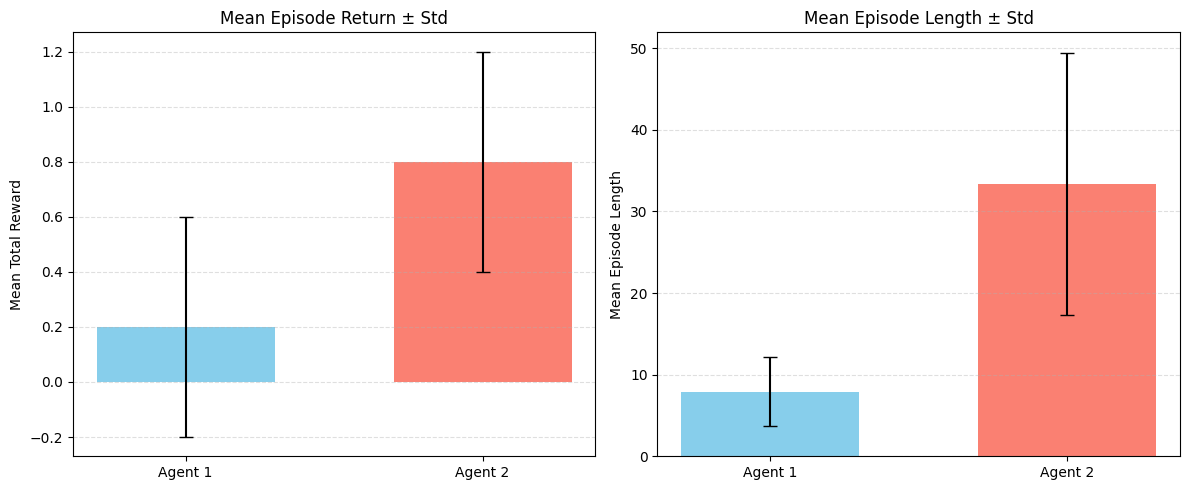

In [ ]:
def compare_policy(
    rewards_run1, lengths_run1,
    rewards_run2, lengths_run2,
    label_run1="Agent 1", label_run2="Agent 2"
):
    """
    Compare two policy runs using mean return and mean episode length.

    Args:
        rewards_run1 (list): Episode rewards for run 1.
        lengths_run1 (list): Episode lengths for run 1.
        rewards_run2 (list): Episode rewards for run 2.
        lengths_run2 (list): Episode lengths for run 2.
        label_run1 (str): Label for run 1.
        label_run2 (str): Label for run 2.
    """

    mean_rewards = [np.mean(rewards_run1), np.mean(rewards_run2)]
    std_rewards  = [np.std(rewards_run1), np.std(rewards_run2)]

    mean_lengths = [np.mean(lengths_run1), np.mean(lengths_run2)]
    std_lengths  = [np.std(lengths_run1), np.std(lengths_run2)]

    labels = [label_run1, label_run2]
    x = np.arange(len(labels))
    width = 0.6

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Mean Rewards
    axes[0].bar(x, mean_rewards, yerr=std_rewards, capsize=5, width=width, color=['skyblue', 'salmon'])
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(labels)
    axes[0].set_ylabel("Mean Total Reward")
    axes[0].set_title("Mean Episode Return ± Std")
    axes[0].grid(True, axis="y", linestyle="--", alpha=0.4)

    # Mean Episode Lengths
    axes[1].bar(x, mean_lengths, yerr=std_lengths, capsize=5, width=width, color=['skyblue', 'salmon'])
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(labels)
    axes[1].set_ylabel("Mean Episode Length")
    axes[1].set_title("Mean Episode Length ± Std")
    axes[1].grid(True, axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

compare_policy(agent_1_returns, agent_1_lengths, agent_2_returns, agent_2_lengths)

15. Explique quais fatores levaram às diferenças observadas entre as políticas obtidas no ambiente determinístico e no ambiente escorregadio.

As diferenças entre as políticas obtidas no ambiente determinístico e no ambiente escorregadio surgem da aleatoriedade gerada pelo fator de escorregamento. No ambiente determinístico, a política ótima privilegia sempre o caminho mais curto até o objetivo, pois não existe incerteza nas transições. Já no ambiente escorregadio, a política ótima deve considerar a probabilidade de desviar da ação escolhida e, portanto, tende a priorizar trajetórias mais seguras, mesmo que isso aumente o número de passos.

**1. Natureza do ambiente**  
No ambiente determinístico, as ações possuem efeito certo: mover para esquerda leva exatamente para a esquerda. Já no ambiente escorregadio, cada ação tem 1/3 de chance de ser executada corretamente e 2/3 de chance de resultar em uma direção perpendicular. Essa diferença na dinâmica altera muito as estratégias mais vantajosas.

**2. Objetivo do agente (maximizar retorno esperado)**  
O agente busca sempre maximizar a recompensa esperada. No ambiente determinístico, isso significa escolher o caminho mais curto até o objetivo. No ambiente escorregadio, porém, caminhos curtos que passam perto de buracos tornam-se arriscados, pois o deslizamento pode levar o agente a cair em estados terminais. Assim, a política ótima pode preferir rotas mais longas, mas que oferecem maior segurança e maior probabilidade de sucesso.

**3. Processo de aprendizado (Policy Iteration)**  
O algoritmo de *Policy Iteration* ajusta a política de acordo com a dinâmica observada no ambiente. Quando treinado no ambiente determinístico, o agente aprende trajetórias eficientes apenas nesse contexto. Já no ambiente escorregadio, o aprendizado incorpora a estocasticidade, resultando em políticas mais robustas ao ruído, ainda que menos eficientes em termos de número de passos.

Portanto, como o teste é realisado no ambiente escorregadio, a política treinada nesse tipo de ambiente obteve melhores resultados, pois já considerava as chances de escorregar. Já a política determisnística não contava com a possibilidade de escorregar, porque não foi treinada para isso, e obteve um desempenho pior.

16. Quais estratégias poderiam ser adotadas para tornar o comportamento do agente menos conservador quando treinado no ambiente escorregadio?

Quando o agente é treinado no ambiente escorregadio, sua política tende a ser mais conservadora, dando preferência à trajetórias seguras em detrimento da eficiência. No entanto, existem algumas estratégias que podem ser adotadas para tornar o comportamento menos conservador:

**1. Ajuste do fator de desconto (γ)**  
Um valor mais alto de γ dá maior importância a recompensas futuras, incentivando o agente a planejar caminhos mais longos e seguros. Já valores menores de γ fazem o agente valorizar recompensas imediatas, o que pode levá-lo a arriscar trajetórias mais curtas em direção ao objetivo.

**2. Modificação da função de recompensa**  
Atualmente, o agente recebe recompensa apenas ao alcançar o objetivo. Alterar a função de recompensa, por exemplo, atribuindo pequenas penalidades por cada passo ou pequenas recompensas por avançar em direção ao objetivo, pode incentivar trajetórias mais rápidas e menos conservadoras.

**3. Variações no processo de exploração**  
Se o treinamento for realizado com algum algoritmo que envolva exploração (como *Q-Learning* ou *SARSA*), aumentar a taxa de exploração (ε em ε-greedy, por exemplo) pode levar o agente a experimentar rotas alternativas mais arriscadas, mas possivelmente mais eficientes.

**4. Alteração na modelagem da estocasticidade**  
Outra estratégia seria reduzir a probabilidade de deslizar, tornando o ambiente menos escorregadio. Isso diminuiria a incerteza, permitindo que o agente escolha rotas mais diretas.